In [5]:
%pip install requests beautifulsoup4 pandas

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [19]:
import requests
from bs4 import BeautifulSoup
import pandas as pd
from urllib.parse import urljoin

In [8]:
url = "https://nva.nielit.gov.in/courses.php"

response = requests.get(url, timeout=20)

print("Status Code:", response.status_code)
print("Website URL:", response.url)
print("HTML Content Length:", len(response.text))

Status Code: 200
Website URL: https://nva.nielit.gov.in/courses.php
HTML Content Length: 174091


In [9]:
soup = BeautifulSoup(response.text, "html.parser")

print("Page Title:", soup.title.text)

print("\nHTML Preview:\n")
print(soup.prettify()[:3000])

Page Title: NIELIT Virtual Academy (NVA) : COURSES PAGE 

HTML Preview:

<!DOCTYPE html>
<html lang="en">
 <head>
  <meta charset="utf-8"/>
  <meta content="width=device-width, initial-scale=1" name="viewport"/>
  <title>
   NIELIT Virtual Academy (NVA) : COURSES PAGE
  </title>
  <link href="./css/courses_v1.0.css" rel="stylesheet"/>
  <link href="./assets/images/favicon.png" rel="shortcut icon"/>
 </head>
 <body style="display:block">
  <!DOCTYPE html>
  <html lang="en">
   <head>
    <meta charset="utf-8"/>
    <meta content="width=device-width, initial-scale=1.0" name="viewport"/>
    <title>
     NIELIT Virtual Academy (NVA)
    </title>
    <link href="./assets/images/favicon.png" rel="shortcut icon"/>
    <!-- link start used for all the page -->
    <!-- section for normal page -->
    <link href="scripts/font-awesome-min.css" rel="stylesheet"/>
    <!-- used for font -->
    <script src="scripts/jquery-3_6.js">
    </script>
    <!-- javascript -->
    <link href="scripts/boos

In [10]:
# Website ke saare headings find karna
headings = soup.find_all(["h1", "h2", "h3", "h4"])

for heading in headings:
    print(heading.get_text(strip=True))

COURSES
Certificate Course in Structured Query Language using MySQL
Certificate Course in Front-End Development (Self-Paced)
Certificate Course in Artificial Intelligence and Machine Learning using Python
Introduction to Generative AI
Introduction to IoT Data Analyst
Introduction to Agentic AI
Introduction to NoSQL
Introduction to FPGA Prototyping using Verilog HDL
Introduction to Static Timing Analysis
Introduction to VLSI Fundamentals
Introduction to Device Driver Development
3D Printing: Design and Development Fundamentals
Introduction to Verilog Programming
CCC - Self Paced Learning (FREE)


In [11]:
keywords = ["Course", "Fee", "Price", "Duration", "MySQL", "Generative AI"]

for keyword in keywords:
    results = soup.find_all(string=lambda text: text and keyword.lower() in text.lower())

    print(f"\n--- {keyword} ---")

    for result in results[:5]:
        print(result.strip())


--- Course ---
NIELIT Virtual Academy (NVA) : COURSES PAGE
Courses
Mobile nav row: Courses, LMS, Search Icon or X
Courses
function logoutConfirmation1(event) {
                event.preventDefault();
                
            Swal.fire({
                title: 'Redirect to Home page',
                html: 'Are you willing to redirect to the courses page.<br> You will need to login again.',
                icon: 'warning',
                showCancelButton: true,
                confirmButtonText: 'OK',
                cancelButtonText: 'Cancel',
                confirmButtonColor: '#d33',
                cancelButtonColor: '#3085d6'
            }).then((result) => {
                if (result.isConfirmed) {
                    const form = document.createElement("form");
                    form.method = "POST";
                    form.action = "https://nva.nielit.gov.in/loginProcess.php";
                    const input = document.createElement("input");
                    input

In [12]:
# Ek course ka naam search karna
course = soup.find(string=lambda text: text and "Structured Query Language" in text)

# Course ke parent HTML elements inspect karna
if course:
    print(course.parent.parent.prettify()[:3000])
else:
    print("Course not found")

<div style="height:auto; text-align:center;">
 <h3>
  Certificate Course in Structured Query Language using MySQL
 </h3>
</div>



In [13]:
course_headings = soup.find_all("h3")

course_names = []

for heading in course_headings:
    course_name = heading.get_text(strip=True)

    if course_name:
        course_names.append(course_name)

print("Total Courses:", len(course_names))

for index, name in enumerate(course_names, start=1):
    print(index, name)

Total Courses: 13
1 Certificate Course in Structured Query Language using MySQL
2 Certificate Course in Front-End Development (Self-Paced)
3 Certificate Course in Artificial Intelligence and Machine Learning using Python
4 Introduction to Generative AI
5 Introduction to IoT Data Analyst
6 Introduction to Agentic AI
7 Introduction to NoSQL
8 Introduction to FPGA Prototyping using Verilog HDL
9 Introduction to Static Timing Analysis
10 Introduction to VLSI Fundamentals
11 Introduction to Device Driver Development
12 3D Printing: Design and Development Fundamentals
13 Introduction to Verilog Programming


In [14]:
# First course ka HTML element find karna
first_course = soup.find(
    string=lambda text: text and "Structured Query Language" in text
)

# Course ke 3 levels upar ka container
if first_course:
    course_container = first_course.parent.parent.parent

    print(course_container.prettify()[:6000])
else:
    print("Course not found")

<div class="eachdiv" data-department="SELF PACED" style="position: relative; padding:3px; overflow:hidden; ">
 <span class="badge position-absolute" style=" background-color : #08D31E; text-align: center; margin: -1px; top: 20px; left: -29px; transform: rotate(-44deg); z-index: 1; width:120px;">
  SELF PACED
 </span>
 <a href="./prospectus/SP32.pdf" target="preview_blank">
  <font size="4">
  </font>
  <img alt="Img" src="images/SP32.png" style="position:relative; cursor:pointer;  overflow:hidden;"/>
  <i class="h4 text-danger" onmouseout="this.style.background='rgba(255,255,255,0.85)';" onmouseover="window._pdfIconHovered=true; this.style.background='rgba(181, 165, 165, 0.61)'" style="position:absolute; top:10px; right:10px; background:rgba(255,255,255,0.85); border-radius:50%; padding:0px 3px 6px 6px; z-index:2; cursor:pointer;" title="Download Prospectus">
   <svg class="bi bi-filetype-pdf" fill="currentColor" height="25" viewbox="0 0 16 16" width="25" xmlns="http://www.w3.org/2000/

In [15]:
# Website ke saare course containers find karna
course_cards = soup.find_all("div", class_="eachdiv")

print("Total Course Cards:", len(course_cards))

Total Course Cards: 13


In [16]:
# Har course card se information extract karna
for card in course_cards:

    # Course name
    heading = card.find("h3")
    course_name = heading.get_text(strip=True) if heading else "Not Available"

    # Course fee
    fee_tag = card.find("p", string=lambda text: text and "Course Fee" in text)
    course_fee = fee_tag.get_text(strip=True) if fee_tag else "Not Available"

    # Course type
    course_type = card.get("data-department", "Not Available")

    print("Course Name:", course_name)
    print("Course Fee:", course_fee)
    print("Course Type:", course_type)
    print("-" * 60)

Course Name: Certificate Course in Structured Query Language using MySQL
Course Fee: Course Fee : ₹600/-
Course Type: SELF PACED
------------------------------------------------------------
Course Name: Certificate Course in Front-End Development (Self-Paced)
Course Fee: Course Fee : ₹600/-
Course Type: SELF PACED
------------------------------------------------------------
Course Name: Certificate Course in Artificial Intelligence and Machine Learning using Python
Course Fee: Course Fee : ₹600/-
Course Type: SELF PACED
------------------------------------------------------------
Course Name: Introduction to Generative AI
Course Fee: Course Fee : ₹59/-
Course Type: SELF PACED
------------------------------------------------------------
Course Name: Introduction to IoT Data Analyst
Course Fee: Course Fee : ₹59/-
Course Type: SELF PACED
------------------------------------------------------------
Course Name: Introduction to Agentic AI
Course Fee: Course Fee : ₹59/-
Course Type: SELF PAC

In [17]:
for card in course_cards:

    # Prospectus PDF link
    prospectus_tag = card.find("a", href=True)
    prospectus_link = prospectus_tag["href"] if prospectus_tag else "Not Available"

    # Apply button
    apply_tag = card.find("a", class_="listed_course_apply")
    batch_id = apply_tag.get("data-batch_id") if apply_tag else "Not Available"

    print("Prospectus Link:", prospectus_link)
    print("Batch ID:", batch_id)
    print("-" * 60)

Prospectus Link: ./prospectus/SP32.pdf
Batch ID: 401
------------------------------------------------------------
Prospectus Link: ./prospectus/SP31.pdf
Batch ID: 402
------------------------------------------------------------
Prospectus Link: ./prospectus/SP33.pdf
Batch ID: 403
------------------------------------------------------------
Prospectus Link: ./prospectus/SP36.pdf
Batch ID: 457
------------------------------------------------------------
Prospectus Link: ./prospectus/SP11.pdf
Batch ID: 505
------------------------------------------------------------
Prospectus Link: ./prospectus/SP39.pdf
Batch ID: 504
------------------------------------------------------------
Prospectus Link: ./prospectus/SP310.pdf
Batch ID: 506
------------------------------------------------------------
Prospectus Link: ./prospectus/SP13.pdf
Batch ID: 664
------------------------------------------------------------
Prospectus Link: ./prospectus/SP14.pdf
Batch ID: 665
----------------------------------

In [18]:
base_url = "https://nva.nielit.gov.in/courses.php"

for card in course_cards:

    prospectus_tag = card.find("a", href=True)

    if prospectus_tag:
        relative_link = prospectus_tag["href"]

        absolute_link = urljoin(base_url, relative_link)

        print("Relative URL:", relative_link)
        print("Absolute URL:", absolute_link)
        print("-" * 60)

Relative URL: ./prospectus/SP32.pdf
Absolute URL: https://nva.nielit.gov.in/prospectus/SP32.pdf
------------------------------------------------------------
Relative URL: ./prospectus/SP31.pdf
Absolute URL: https://nva.nielit.gov.in/prospectus/SP31.pdf
------------------------------------------------------------
Relative URL: ./prospectus/SP33.pdf
Absolute URL: https://nva.nielit.gov.in/prospectus/SP33.pdf
------------------------------------------------------------
Relative URL: ./prospectus/SP36.pdf
Absolute URL: https://nva.nielit.gov.in/prospectus/SP36.pdf
------------------------------------------------------------
Relative URL: ./prospectus/SP11.pdf
Absolute URL: https://nva.nielit.gov.in/prospectus/SP11.pdf
------------------------------------------------------------
Relative URL: ./prospectus/SP39.pdf
Absolute URL: https://nva.nielit.gov.in/prospectus/SP39.pdf
------------------------------------------------------------
Relative URL: ./prospectus/SP310.pdf
Absolute URL: https:/

In [20]:
# Data store karne ke liye empty lists
course_data = []

base_url = "https://nva.nielit.gov.in/courses.php"

for card in course_cards:

    # Course Name
    heading = card.find("h3")
    course_name = heading.get_text(strip=True) if heading else "Not Available"

    # Course Fee
    fee_tag = card.find("p", string=lambda text: text and "Course Fee" in text)
    course_fee = fee_tag.get_text(strip=True) if fee_tag else "Not Available"

    # Course Type
    course_type = card.get("data-department", "Not Available")

    # Prospectus URL
    prospectus_tag = card.find("a", href=True)
    prospectus_url = (
        urljoin(base_url, prospectus_tag["href"])
        if prospectus_tag else "Not Available"
    )

    # Batch ID
    apply_tag = card.find("a", class_="listed_course_apply")
    batch_id = apply_tag.get("data-batch_id") if apply_tag else "Not Available"

    # Dictionary mein information store karna
    course_data.append({
        "Course Name": course_name,
        "Course Fee": course_fee,
        "Course Type": course_type,
        "Prospectus URL": prospectus_url,
        "Batch ID": batch_id
    })

# Dictionary list ko DataFrame mein convert karna
df = pd.DataFrame(course_data)

# DataFrame display karna
df

,Course Name,Course Fee,Course Type,Prospectus URL,Batch ID
0,Certificate Course in Structured Query Languag...,Course Fee : ₹600/-,SELF PACED,https://nva.nielit.gov.in/prospectus/SP32.pdf,401
1,Certificate Course in Front-End Development (S...,Course Fee : ₹600/-,SELF PACED,https://nva.nielit.gov.in/prospectus/SP31.pdf,402
2,Certificate Course in Artificial Intelligence ...,Course Fee : ₹600/-,SELF PACED,https://nva.nielit.gov.in/prospectus/SP33.pdf,403
3,Introduction to Generative AI,Course Fee : ₹59/-,SELF PACED,https://nva.nielit.gov.in/prospectus/SP36.pdf,457
4,Introduction to IoT Data Analyst,Course Fee : ₹59/-,SELF PACED,https://nva.nielit.gov.in/prospectus/SP11.pdf,505
5,Introduction to Agentic AI,Course Fee : ₹59/-,SELF PACED,https://nva.nielit.gov.in/prospectus/SP39.pdf,504
6,Introduction to NoSQL,Course Fee : ₹59/-,SELF PACED,https://nva.nielit.gov.in/prospectus/SP310.pdf,506
7,Introduction to FPGA Prototyping using Verilog...,Course Fee : ₹600/-,SELF PACED,https://nva.nielit.gov.in/prospectus/SP13.pdf,664
8,Introduction to Static Timing Analysis,Course Fee : ₹600/-,SELF PACED,https://nva.nielit.gov.in/prospectus/SP14.pdf,665
9,Introduction to VLSI Fundamentals,Course Fee : ₹600/-,SELF PACED,https://nva.nielit.gov.in/prospectus/SP15.pdf,666


In [21]:
# Course Fee se unnecessary text remove karna
df["Course Fee"] = df["Course Fee"].str.replace(
    "Course Fee : ", "", regex=False
)

# Updated DataFrame display karna
df

,Course Name,Course Fee,Course Type,Prospectus URL,Batch ID
0,Certificate Course in Structured Query Languag...,₹600/-,SELF PACED,https://nva.nielit.gov.in/prospectus/SP32.pdf,401
1,Certificate Course in Front-End Development (S...,₹600/-,SELF PACED,https://nva.nielit.gov.in/prospectus/SP31.pdf,402
2,Certificate Course in Artificial Intelligence ...,₹600/-,SELF PACED,https://nva.nielit.gov.in/prospectus/SP33.pdf,403
3,Introduction to Generative AI,₹59/-,SELF PACED,https://nva.nielit.gov.in/prospectus/SP36.pdf,457
4,Introduction to IoT Data Analyst,₹59/-,SELF PACED,https://nva.nielit.gov.in/prospectus/SP11.pdf,505
5,Introduction to Agentic AI,₹59/-,SELF PACED,https://nva.nielit.gov.in/prospectus/SP39.pdf,504
6,Introduction to NoSQL,₹59/-,SELF PACED,https://nva.nielit.gov.in/prospectus/SP310.pdf,506
7,Introduction to FPGA Prototyping using Verilog...,₹600/-,SELF PACED,https://nva.nielit.gov.in/prospectus/SP13.pdf,664
8,Introduction to Static Timing Analysis,₹600/-,SELF PACED,https://nva.nielit.gov.in/prospectus/SP14.pdf,665
9,Introduction to VLSI Fundamentals,₹600/-,SELF PACED,https://nva.nielit.gov.in/prospectus/SP15.pdf,666


In [22]:
df.to_csv("nielit_courses.csv", index=False, encoding="utf-8-sig")

print("CSV file successfully created!")

CSV file successfully created!


In [23]:
%pip install matplotlib seaborn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

In [25]:
df["Fee Numeric"] = df["Course Fee"].str.replace(
    r"[^\d.]", "", regex=True
).astype(float)

df[["Course Name", "Course Fee", "Fee Numeric"]]

,Course Name,Course Fee,Fee Numeric
0,Certificate Course in Structured Query Languag...,₹600/-,600.0
1,Certificate Course in Front-End Development (S...,₹600/-,600.0
2,Certificate Course in Artificial Intelligence ...,₹600/-,600.0
3,Introduction to Generative AI,₹59/-,59.0
4,Introduction to IoT Data Analyst,₹59/-,59.0
5,Introduction to Agentic AI,₹59/-,59.0
6,Introduction to NoSQL,₹59/-,59.0
7,Introduction to FPGA Prototyping using Verilog...,₹600/-,600.0
8,Introduction to Static Timing Analysis,₹600/-,600.0
9,Introduction to VLSI Fundamentals,₹600/-,600.0


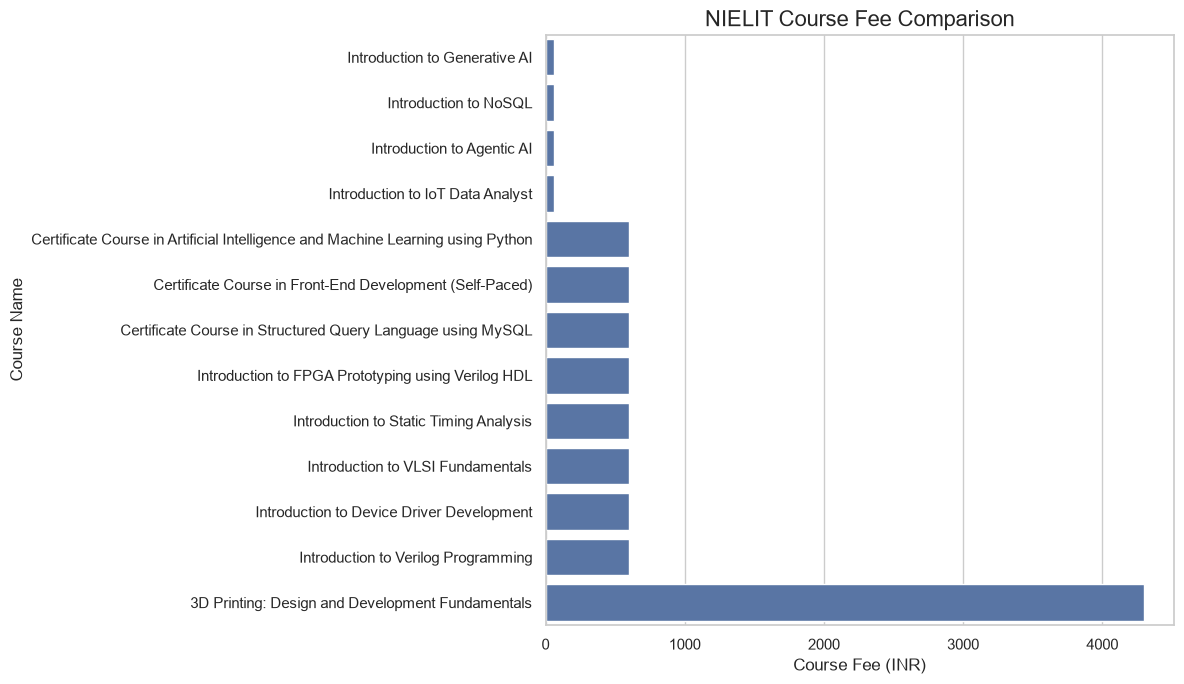

In [29]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=df.sort_values("Fee Numeric", ascending=True),
    x="Fee Numeric",
    y="Course Name"
)

plt.title("NIELIT Course Fee Comparison", fontsize=16)
plt.xlabel("Course Fee (INR)")
plt.ylabel("Course Name")
plt.tight_layout()
plt.show()

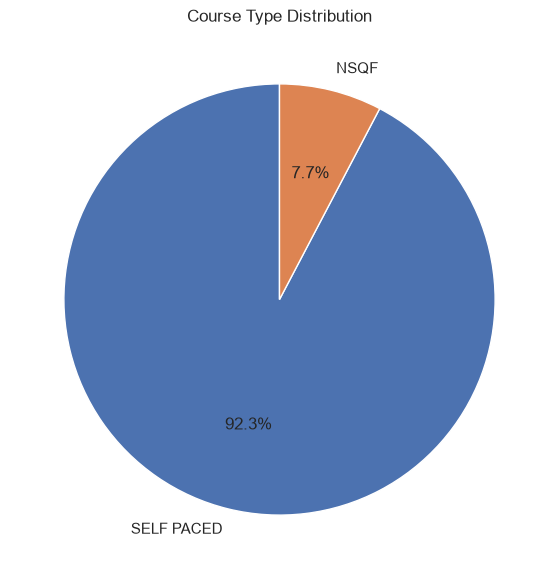

In [27]:
course_counts = df["Course Type"].value_counts()

plt.figure(figsize=(7, 7))

plt.pie(
    course_counts,
    labels=course_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Course Type Distribution")
plt.show()

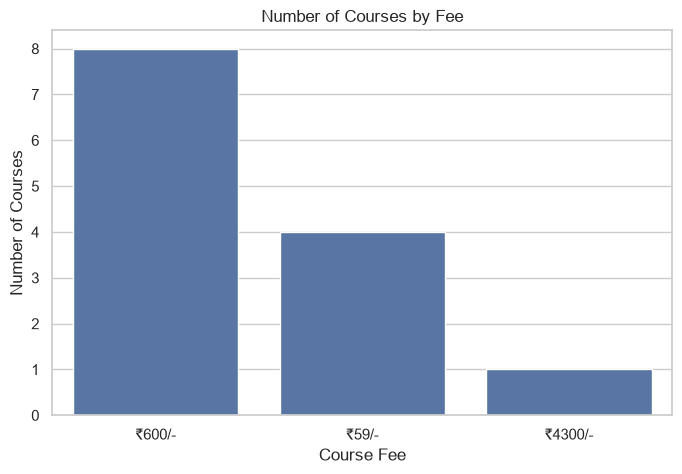

In [28]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Course Fee",
    order=df["Course Fee"].value_counts().index
)

plt.xlabel("Course Fee")
plt.ylabel("Number of Courses")
plt.title("Number of Courses by Fee")

plt.show()

In [30]:
import os
print(os.getcwd())

C:\Users\anami\Web_Scraping_Mini_Project
